In [94]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

In [95]:
# Load data
path = "data/covid19_sg.csv"
df = pd.read_csv(path)


# Inspect columns
print(df.columns)


# Convert date column (adjust name if necessary)
df['Date'] = pd.to_datetime(df['Date'])


df = df.sort_values('Date').reset_index(drop=True)


df.head()

Index(['Date', 'Daily Confirmed', 'False Positives Found',
       'Cumulative Confirmed', 'Daily Discharged',
       'Passed but not due to COVID', 'Cumulative Discharged',
       'Discharged to Isolation', 'Still Hospitalised', 'Daily Deaths',
       'Cumulative Deaths', 'Tested positive demise', 'Daily Imported',
       'Daily Local transmission', 'Local cases residing in dorms MOH report',
       'Local cases not residing in doms MOH report',
       'Intensive Care Unit (ICU)', 'General Wards MOH report',
       'In Isolation MOH report', 'Total Completed Isolation MOH report',
       'Total Hospital Discharged MOH report',
       'Requires Oxygen Supplementation or Unstable', 'Linked community cases',
       'Unlinked community cases', 'Phase', 'Cumulative Vaccine Doses',
       'Cumulative Individuals Vaccinated',
       'Cumulative Individuals Vaccination Completed',
       'Perc population completed at least one dose',
       'Perc population completed vaccination', 'Sinovac vac

,Date,Daily Confirmed,False Positives Found,Cumulative Confirmed,Daily Discharged,Passed but not due to COVID,Cumulative Discharged,Discharged to Isolation,Still Hospitalised,Daily Deaths,...,Cumulative Individuals Vaccinated,Cumulative Individuals Vaccination Completed,Perc population completed at least one dose,Perc population completed vaccination,Sinovac vaccine doses,Cumulative individuals using Sinovac vaccine,Doses of other vaccines recognised by WHO,Cumulative individuals using other vaccines recognised by WHO,Number taken booster shots,Perc population taken booster shots
0,2020-01-23,1,NaN,1,0,0,0,0,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-01-24,2,NaN,3,0,0,0,0,3,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2020-01-25,1,NaN,4,0,0,0,0,4,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2020-01-26,0,NaN,4,0,0,0,0,4,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2020-01-27,1,NaN,5,0,0,0,0,5,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [96]:
# 7-day rolling sum of new cases
df['cases_7d'] = df['Daily Confirmed'].rolling(window=7).sum()


df[['Date', 'Daily Confirmed', 'cases_7d']].head(10)

,Date,Daily Confirmed,cases_7d
0,2020-01-23,1,NaN
1,2020-01-24,2,NaN
2,2020-01-25,1,NaN
3,2020-01-26,0,NaN
4,2020-01-27,1,NaN
5,2020-01-28,2,NaN
6,2020-01-29,3,10.0
7,2020-01-30,3,12.0
8,2020-01-31,3,13.0
9,2020-02-01,2,14.0


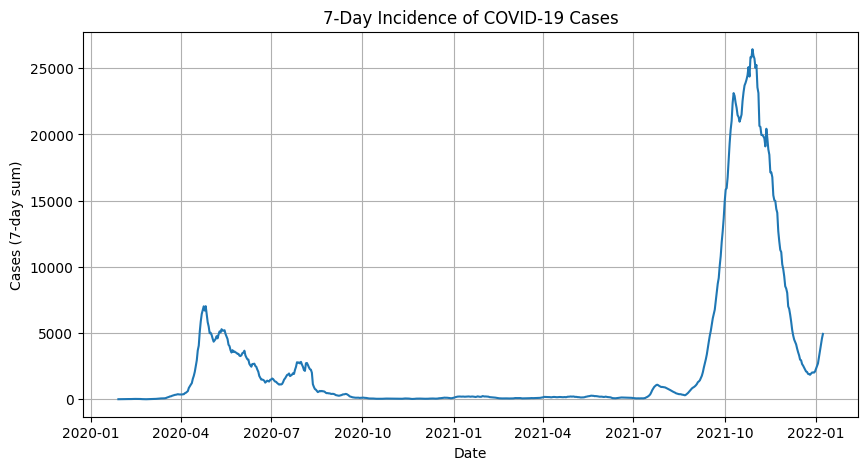

In [97]:
# Visualizing 7-day Incidence
plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['cases_7d'])
plt.title('7-Day Incidence of COVID-19 Cases')
plt.xlabel('Date')
plt.ylabel('Cases (7-day sum)')
plt.grid(True)
plt.show()

In [98]:
# Rolling averages
df['cases_7d_avg'] = df['Daily Confirmed'].rolling(7).mean()
df['hosp_7d_avg'] = df['Still Hospitalised'].rolling(7).mean()


# Hospitalization rate
df['hospitalization_rate'] = df['hosp_7d_avg'] / df['cases_7d_avg']


df[['Date', 'hospitalization_rate']].head(10)

,Date,hospitalization_rate
0,2020-01-23,NaN
1,2020-01-24,NaN
2,2020-01-25,NaN
3,2020-01-26,NaN
4,2020-01-27,NaN
5,2020-01-28,NaN
6,2020-01-29,3.400000
7,2020-01-30,3.833333
8,2020-01-31,4.538462
9,2020-02-01,5.214286


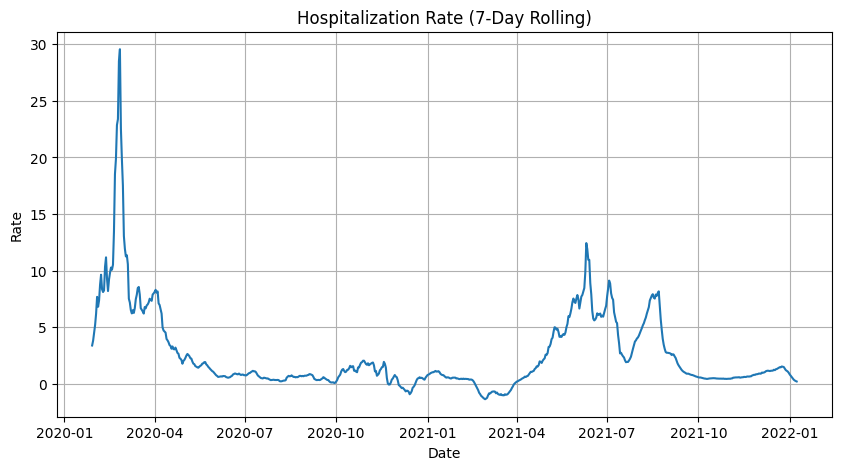

In [99]:
plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['hospitalization_rate'])
plt.title('Hospitalization Rate (7-Day Rolling)')
plt.xlabel('Date')
plt.ylabel('Rate')
plt.grid(True)
plt.show()

In [100]:
# Rolling averages for ICU
df['icu_7d_avg'] = df['Intensive Care Unit (ICU)'].rolling(7).mean()


# Criticality metric
df['criticality'] = df['icu_7d_avg'] / df['hosp_7d_avg']


df[['Date', 'criticality']].head(10)

,Date,criticality
0,2020-01-23,NaN
1,2020-01-24,NaN
2,2020-01-25,NaN
3,2020-01-26,NaN
4,2020-01-27,NaN
5,2020-01-28,NaN
6,2020-01-29,0.0
7,2020-01-30,0.0
8,2020-01-31,0.0
9,2020-02-01,0.0


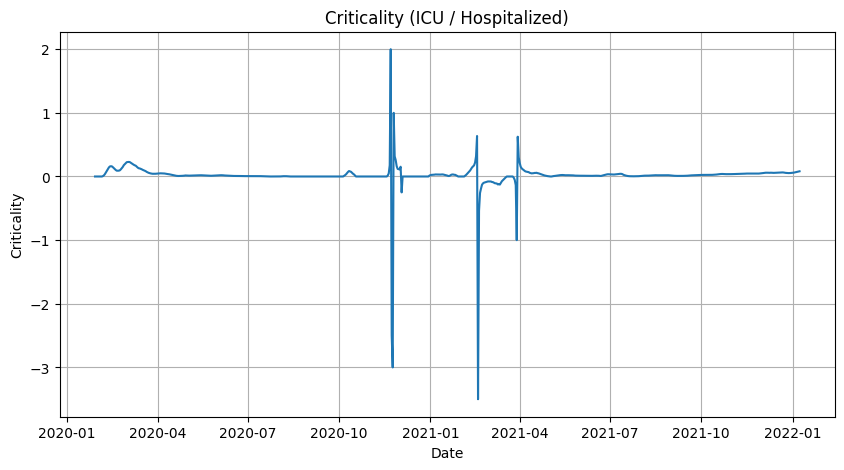

In [101]:
plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['criticality'])
plt.title('Criticality (ICU / Hospitalized)')
plt.xlabel('Date')
plt.ylabel('Criticality')
plt.grid(True)
plt.show()

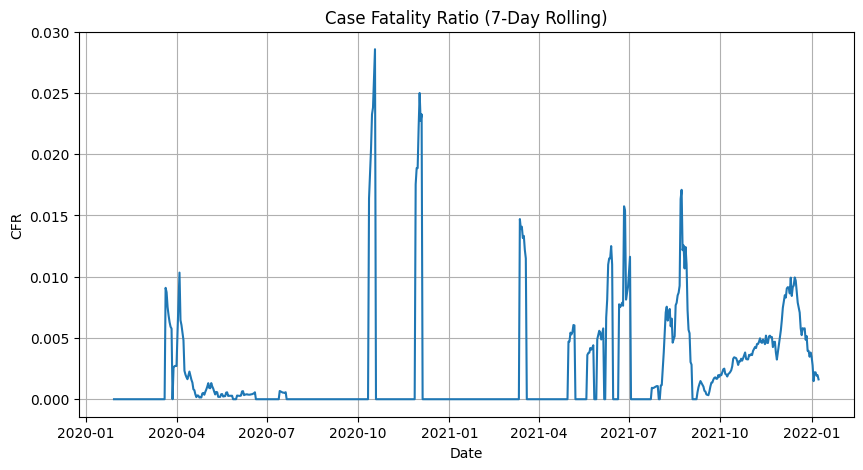

In [102]:
# Rolling averages for deaths
df['deaths_7d_avg'] = df['Daily Deaths'].rolling(7).mean()


# CFR
df['cfr'] = df['deaths_7d_avg'] / df['cases_7d_avg']


plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['cfr'])
plt.title('Case Fatality Ratio (7-Day Rolling)')
plt.xlabel('Date')
plt.ylabel('CFR')
plt.grid(True)
plt.show()

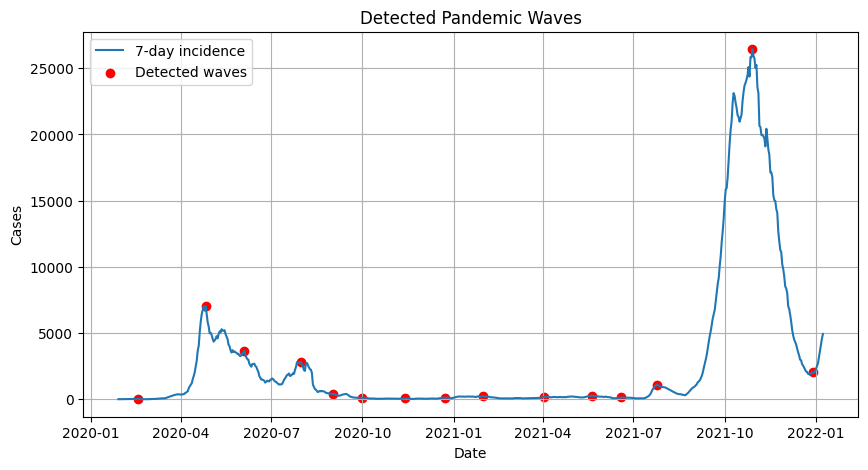

In [103]:
peaks, _ = find_peaks(df['cases_7d'], distance=30)


plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['cases_7d'], label='7-day incidence')
plt.scatter(df.loc[peaks, 'Date'], df.loc[peaks, 'cases_7d'], color='red', label='Detected waves')
plt.legend()
plt.title('Detected Pandemic Waves')
plt.xlabel('Date')
plt.ylabel('Cases')
plt.grid(True)
plt.show()

In [104]:
import os
os.getcwd()

'C:\\Users\\safad\\Desktop\\AI Praktikas\\lab09\\09_CEP'